# 🚀 Clase Práctica: Proceso ETL con Python y Análisis Exploratorio (EDA)

**Objetivo:** Aprender a Extraer, Transformar (limpiar y explorar) y Cargar datos desde cero, aplicando buenas prácticas de la industria como la trazabilidad (logging) y el uso de formatos modernos.

**Autor:** [Tu Nombre]  
**Fecha:** Octubre 2026

In [1]:
# Instalación de dependencias (Descomentar si se usa Google Colab o entorno nuevo)
%pip install pandas numpy matplotlib seaborn pyarrow pyarrow fastparquet

import pandas as pd
import numpy as np
import logging
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración visual de los gráficos
sns.set_theme(style="whitegrid")


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


## 🏗️ Paso 0: Generación del Dataset "Sucio"
En un entorno real, los datos vendrían de una API, una base de datos o un archivo compartido. Para esta clase, generaremos un archivo CSV con errores intencionales: duplicados, nulos, mayúsculas inconsistentes y formatos de fecha mixtos.

In [2]:
# Generamos datos con errores intencionales
datos_sucios = {
    'id_venta': [1, 2, 2, 3, 4, 5, 6, 7, 8, 9],
    'fecha': ['2023-10-01', '2023-10-02', '2023-10-02', '03/10/2023', '2023-10-05', '2023-10-06', '2023-10-07', '2023-10-08', '2023-10-09', '2023-10-10'],
    'cliente': ['Ana', 'Luis', 'Luis', 'Pedro', 'Marta', 'Ana', 'Luis', 'Pedro', 'Marta', 'Ana'],
    'producto': ['Laptop', 'Mouse', 'Mouse', 'Teclado', 'Monitor', 'Laptop', 'Mouse', 'Teclado', 'Monitor', 'Laptop'],
    'categoria': [' electronica ', 'ELECTRONICA', 'electronica', 'Electronica', 'electronica', ' Electronica', 'electronica', 'ELECTRONICA', 'electronica', 'Electronica'],
    'precio': [1000.0, 25.0, 25.0, np.nan, 300.0, 1000.0, 25.0, 45.0, np.nan, 1000.0],
    'cantidad': [1, 2, 2, 1, 1, 1, 3, 1, 1, 1],
    'ciudad': ['Madrid', 'Barcelona', 'Barcelona', 'Madrid', np.nan, 'Madrid', 'Barcelona', 'Madrid', 'Sevilla', np.nan]
}

df_sucio = pd.DataFrame(datos_sucios)
df_sucio.to_csv('ventas_sucias.csv', index=False)
print("✅ Dataset 'ventas_sucias.csv' generado con éxito.")

✅ Dataset 'ventas_sucias.csv' generado con éxito.


## ⚙️ Configuración de Trazabilidad (Logging)
> 💡 *Nota para el alumno:* En procesos ETL profesionales, no basta con que el código funcione; debemos dejar un rastro (log) de qué pasó, cuándo y si hubo errores. Esto reemplaza a las tablas de control complejas para este ejercicio introductorio.

In [3]:
# Configuramos el sistema de logging
logging.basicConfig(
    level=logging.INFO,
    format='%(asctime)s - %(levelname)s - %(message)s',
    filename='proceso_etl.log',
    filemode='w', # 'w' sobreescribe el archivo en cada ejecución
    encoding='utf-8',
    force=True
)

# Para ver los logs también en la salida del Notebook
console = logging.StreamHandler()
console.setLevel(logging.INFO)
logging.getLogger().addHandler(console)

logging.info("=== INICIO DEL PROCESO ETL ===")

=== INICIO DEL PROCESO ETL ===


## 📥 FASE 1: EXTRACCIÓN (Extract)
Leemos los datos desde la fuente. Usamos un bloque `try-except` para manejar errores de forma controlada.

In [4]:
def extraer_datos(ruta_archivo):
    logging.info(f"Iniciando extracción desde: {ruta_archivo}")
    try:
        df = pd.read_csv(ruta_archivo)
        logging.info(f"Extracción exitosa. Registros cargados: {len(df)}")
        return df
    except Exception as e:
        logging.error(f"Error al extraer datos: {e}")
        raise

# Ejecutamos la extracción
df_crudo = extraer_datos('ventas_sucias.csv')
df_crudo.head()

Iniciando extracción desde: ventas_sucias.csv
Extracción exitosa. Registros cargados: 10


,id_venta,fecha,cliente,producto,categoria,precio,cantidad,ciudad
0,1,2023-10-01,Ana,Laptop,electronica,1000.0,1,Madrid
1,2,2023-10-02,Luis,Mouse,ELECTRONICA,25.0,2,Barcelona
2,2,2023-10-02,Luis,Mouse,electronica,25.0,2,Barcelona
3,3,03/10/2023,Pedro,Teclado,Electronica,NaN,1,Madrid
4,4,2023-10-05,Marta,Monitor,electronica,300.0,1,NaN


## 🔄 FASE 2: TRANSFORMACIÓN Y EDA (Transform) - Parte 1: Auditoría y Duplicados
Antes de limpiar, debemos **diagnosticar**. El Análisis Exploratorio de Datos (EDA) nos dice *qué* está mal antes de decidir *cómo* arreglarlo.

In [5]:
logging.info("Iniciando fase de Transformación y EDA...")

# 1. Auditoría inicial
logging.info(f"Forma original del dataset: {df_crudo.shape}")
logging.info(f"Valores nulos por columna:\n{df_crudo.isnull().sum()}")

# 2. Manejo de Duplicados
duplicados = df_crudo.duplicated().sum()
logging.info(f"Filas duplicadas encontradas: {duplicados}")

if duplicados > 0:
    df_limpio = df_crudo.drop_duplicates().reset_index(drop=True)
    logging.info("Duplicados eliminados.")
else:
    df_limpio = df_crudo.copy()

Iniciando fase de Transformación y EDA...
Forma original del dataset: (10, 8)
Valores nulos por columna:
id_venta     0
fecha        0
cliente      0
producto     0
categoria    0
precio       2
cantidad     0
ciudad       2
dtype: int64
Filas duplicadas encontradas: 0


## 🔄 FASE 2: TRANSFORMACIÓN - Parte 2: Limpieza de Texto y Nulos (con EDA)
- **Texto:** Unificaremos la columna `categoria` usando `.str.strip()` y `.str.title()`.
- **Nulos:** No imputamos a ciegas. Primero graficamos la distribución del `precio` para decidir si usar media o mediana.

- El método .strip() elimina los espacios en blanco y los caracteres iniciales y finales de una cadena de texto
- El método str.title() convierte el primer carácter de cada palabra en mayúscula y transforma el resto de las letras de cada palabra a minúsculas

Categoría estandarizada (strip + title).


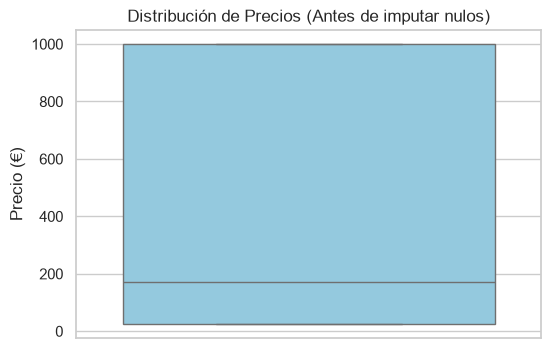

Nulos en 'precio' imputados con la mediana: 172.5€
Nulos en 'ciudad' imputados con la moda: Madrid


In [6]:
# 3. Estandarización de Texto
df_limpio['categoria'] = df_limpio['categoria'].str.strip().str.title()
logging.info("Categoría estandarizada (strip + title).")

# 4. EDA Visual para decidir imputación de nulos
plt.figure(figsize=(6, 4))
sns.boxplot(data=df_limpio, y='precio', color='skyblue')
plt.title('Distribución de Precios (Antes de imputar nulos)')
plt.ylabel('Precio (€)')
plt.show()

# Imputación: Mediana para precio (robusta a outliers), Moda para ciudad
mediana_precio = df_limpio['precio'].median()
df_limpio['precio'] = df_limpio['precio'].fillna(mediana_precio)
logging.info(f"Nulos en 'precio' imputados con la mediana: {mediana_precio}€")

moda_ciudad = df_limpio['ciudad'].mode()[0]
df_limpio['ciudad'] = df_limpio['ciudad'].fillna(moda_ciudad)
logging.info(f"Nulos en 'ciudad' imputados con la moda: {moda_ciudad}")

## 🔄 FASE 2: TRANSFORMACIÓN - Parte 3: Tipos de Datos y Nuevas Columnas
Corregimos los formatos (especialmente las fechas, que vienen mezcladas) y creamos una columna de negocio (`valor_total`).

In [8]:
# 5. Corrección de Tipos de Datos
# errors='coerce' convierte fechas inválidas en NaT en lugar de romper el código
#df_limpio['fecha'] = pd.to_datetime(df_limpio['fecha'], dayfirst=True, errors='coerce')
df_limpio['fecha'] = pd.to_datetime(df_limpio['fecha'], format='mixed', dayfirst=True, errors='coerce')
df_limpio['cantidad'] = df_limpio['cantidad'].astype(int)
logging.info("Tipos de datos convertidos correctamente.")

# 6. Ingeniería de características (Feature Engineering)
df_limpio['valor_total'] = df_limpio['precio'] * df_limpio['cantidad']

logging.info(f"Forma final del dataset: {df_limpio.shape}")
print("\n--- VISTA PREVIA DE DATOS LIMPIOS ---")
display(df_limpio.head())

Tipos de datos convertidos correctamente.
Forma final del dataset: (10, 9)



--- VISTA PREVIA DE DATOS LIMPIOS ---


,id_venta,fecha,cliente,producto,categoria,precio,cantidad,ciudad,valor_total
0,1,2023-01-10,Ana,Laptop,Electronica,1000.0,1,Madrid,1000.0
1,2,2023-02-10,Luis,Mouse,Electronica,25.0,2,Barcelona,50.0
2,2,2023-02-10,Luis,Mouse,Electronica,25.0,2,Barcelona,50.0
3,3,NaT,Pedro,Teclado,Electronica,172.5,1,Madrid,172.5
4,4,2023-05-10,Marta,Monitor,Electronica,300.0,1,Madrid,300.0


## 📤 FASE 3: CARGA (Load)
Guardamos los datos limpios. Usaremos dos formatos:
1. **CSV:** Universal y legible por humanos.
2. **Parquet:** Formato columnar moderno, mucho más rápido y ligero, estándar en ingeniería de datos actual.

In [9]:
def cargar_datos(df, ruta_base):
    logging.info(f"Iniciando carga de datos...")
    try:
        ruta_csv = ruta_base.replace('.csv', '_limpio.csv')
        ruta_parquet = ruta_base.replace('.csv', '_limpio.parquet')
        
        df.to_csv(ruta_csv, index=False)
        df.to_parquet(ruta_parquet, index=False)
        
        logging.info(f"✅ Carga completada exitosamente en:\n - {ruta_csv}\n - {ruta_parquet}")
    except Exception as e:
        logging.error(f"Error al cargar datos: {e}")
        raise

# Ejecutamos la carga
cargar_datos(df_limpio, 'ventas_sucias.csv')
logging.info("=== FIN DEL PROCESO ETL ===")

Iniciando carga de datos...
✅ Carga completada exitosamente en:
 - ventas_sucias_limpio.csv
 - ventas_sucias_limpio.parquet
=== FIN DEL PROCESO ETL ===


## 🎯 Conclusiones y Próximos Pasos
1. Revisa el archivo `proceso_etl.log` que se ha generado en tu carpeta. ¡Ahí está el historial de tu trabajo!
2. Observa cómo el EDA (el gráfico de caja) nos ayudó a tomar una decisión informada sobre los nulos.
3. **Reto:** Intenta modificar el código para que agrupe las ventas por `categoria` y muestre el `valor_total` acumulado antes de guardar el archivo.

*(Fin de la clase)*